# HealthAware — Decision Tree Baseline Model

## 1. Data Loading and Initial Quality Checks

This notebook documents the data preparation, exploratory data analysis,
training, testing, and validation of a baseline machine-learning model
for the HealthAware project.

In [7]:
import pandas as pd

In [8]:
# Load the diabetes dataset from the project's data folder
df = pd.read_csv("data/diabetes_012_health_indicators_BRFSS2015.csv")

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Count all missing values
print("Missing values:", df.isnull().sum().sum())

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Display the number of records in each target class
print("\nTarget distribution:")
print(df["Diabetes_012"].value_counts().sort_index())

Dataset shape: (253680, 22)
Missing values: 0
Duplicate rows: 23899

Target distribution:
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


In [9]:
# Check whether identical feature values have different target labels
feature_columns = df.columns.drop("Diabetes_012")

duplicate_features = df.duplicated(
    subset=feature_columns,
    keep=False
)

print(
    "Rows with repeated feature combinations:",
    duplicate_features.sum()
)

print("\nTarget distribution among these rows:")
print(
    df.loc[duplicate_features, "Diabetes_012"]
      .value_counts()
      .sort_index()
)

Rows with repeated feature combinations: 38000

Target distribution among these rows:
Diabetes_012
0.0    35723
1.0      340
2.0     1937
Name: count, dtype: int64


In [10]:
# Group records by all input features and count distinct target labels
target_variation = (
    df.groupby(list(feature_columns))["Diabetes_012"]
      .nunique()
)

# Count feature combinations associated with more than one target label
conflicting_combinations = (target_variation > 1).sum()

print(
    "Feature combinations with conflicting target labels:",
    conflicting_combinations
)
print(
    "Total distinct feature combinations:",
    len(target_variation)
)

Feature combinations with conflicting target labels: 1834
Total distinct feature combinations: 227908


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is the process of examining a dataset using
summary statistics and visualizations to understand its distribution,
identify patterns, and guide machine-learning decisions.

This section investigates the target-class distribution and selected
health indicators in the HealthAware dataset.

In [11]:
# Count records in each target class
target_counts = df["Diabetes_012"].value_counts().sort_index()

# Calculate the percentage represented by each class
target_percentages = (
    df["Diabetes_012"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Combine the counts and percentages into one table
target_summary = pd.DataFrame({
    "Record Count": target_counts,
    "Percentage (%)": target_percentages.round(2)
})

display(target_summary)

,Record Count,Percentage (%)
Diabetes_012,,
0.0,213703,84.24
1.0,4631,1.83
2.0,35346,13.93


In [12]:
# Count the records in each diabetes category
target_counts = df["Diabetes_012"].value_counts().sort_index()

# Display the counts to verify the variable
print(target_counts)

Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


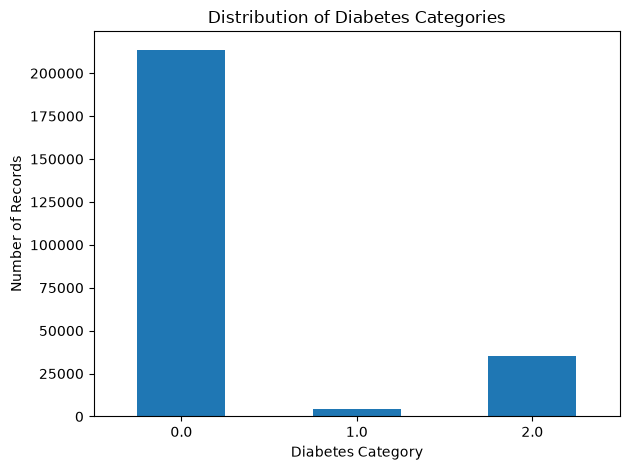

In [13]:
import matplotlib.pyplot as plt

# Create a bar chart of the target classes
target_counts.plot(kind="bar")

plt.title("Distribution of Diabetes Categories")
plt.xlabel("Diabetes Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.2 Distribution of Age and BMI

This section examines the distribution of age categories and Body Mass
Index (BMI) to understand the characteristics of the dataset

In [14]:
# Display summary statistics for BMI and Age
print("BMI summary:")
print(df["BMI"].describe())

print("\nAge category counts:")
print(df["Age"].value_counts().sort_index())

BMI summary:
count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          98.000000
Name: BMI, dtype: float64

Age category counts:
Age
1.0      5700
2.0      7598
3.0     11123
4.0     13823
5.0     16157
6.0     19819
7.0     26314
8.0     30832
9.0     33244
10.0    32194
11.0    23533
12.0    15980
13.0    17363
Name: count, dtype: int64


### 2.3 BMI Distribution

A histogram is used to examine the distribution of BMI values, including
their spread, concentration, and extreme values.

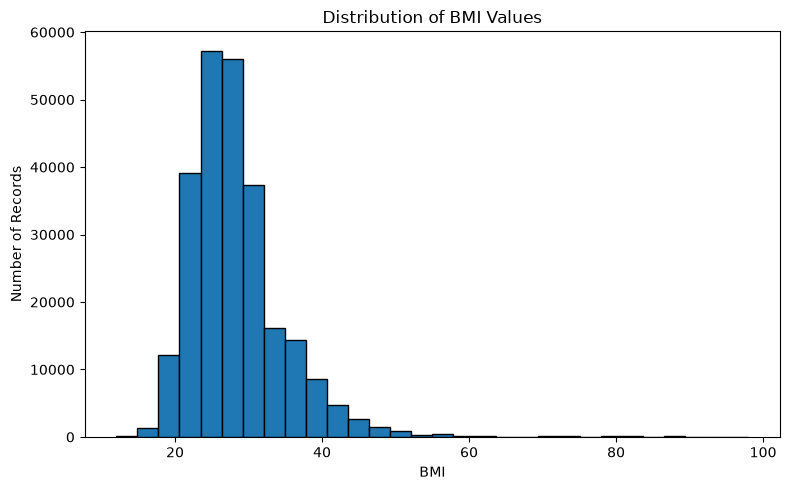

In [15]:
import matplotlib.pyplot as plt

# Plot the distribution of BMI values
plt.figure(figsize=(8, 5))
plt.hist(df["BMI"], bins=30, edgecolor="black")

plt.title("Distribution of BMI Values")
plt.xlabel("BMI")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### 2.4 BMI Across Diabetes Categories

This section compares BMI values across the three target classes using
summary statistics and a boxplot. It helps us understand whether the
distribution of BMI differs between the classes.

In [16]:
# Calculate BMI summary statistics for each diabetes category
bmi_by_class = df.groupby("Diabetes_012")["BMI"].describe()

display(bmi_by_class)

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,,,,,,,,
0.0,213703.0,27.742521,6.260993,12.0,24.0,27.0,30.0,98.0
1.0,4631.0,30.724466,6.964898,13.0,26.0,30.0,34.0,96.0
2.0,35346.0,31.944011,7.363401,13.0,27.0,31.0,35.0,98.0


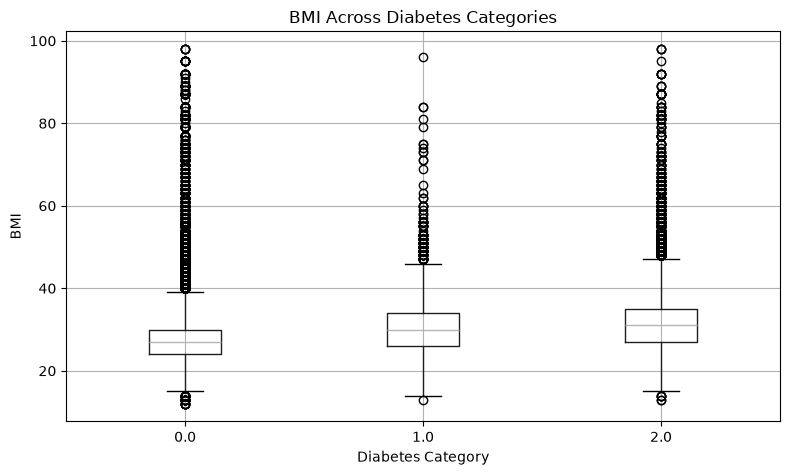

In [17]:
# Compare BMI distributions across diabetes categories
df.boxplot(column="BMI", by="Diabetes_012", figsize=(8, 5))

plt.title("BMI Across Diabetes Categories")
plt.suptitle("")
plt.xlabel("Diabetes Category")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

**Observation 5 — BMI across diabetes categories**

The boxplot shows that the median BMI is higher in the prediabetes and
diabetes categories than in the no-diabetes category. The distributions
also contain potential outliers. This suggests that BMI may be a useful
predictive feature, although the observed association does not establish
causation.

### 2.5 High Blood Pressure Across Diabetes Categories

This section compares the proportion of records with high blood pressure
across the three diabetes categories.

In [18]:
# Calculate the proportion with high blood pressure in each category
high_bp_by_class = df.groupby("Diabetes_012")["HighBP"].mean() * 100

print("Percentage with high blood pressure by diabetes category:")
print(high_bp_by_class.round(2))

Percentage with high blood pressure by diabetes category:
Diabetes_012
0.0    37.11
1.0    62.90
2.0    75.27
Name: HighBP, dtype: float64


**Observation 6 — High blood pressure across diabetes categories**

The proportion of records with high blood pressure increases from 37.11%
in the no-diabetes category to 62.90% in the prediabetes category and
75.27% in the diabetes category. This association suggests that the
HighBP feature may be useful for classification, but it does not establish
causation or guarantee predictive performance.

In [19]:
# Display every column and its data type
print(df.dtypes)

# Display the distinct values in the target column
print("\nTarget values:")
print(sorted(df["Diabetes_012"].unique()))

Diabetes_012            float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

Target values:
[np.float64(0.0), np.float64(1.0), np.float64(2.0)]


## 3. Data Preparation

Data preparation involves organizing and checking the dataset before
training a machine-learning model. This includes identifying the target
variable, separating input features from the target, checking data
quality, and preparing training and testing datasets.

For HealthAware, `Diabetes_012` is the target variable, while the
remaining 21 columns are candidate input features.

In [20]:
# Separate input features from the target variable
X = df.drop(columns=["Diabetes_012"])

# Store the target variable separately
y = df["Diabetes_012"]

# Verify the dimensions
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

Feature matrix shape: (253680, 21)
Target vector shape: (253680,)


### 3.1 Train-Test Split

The dataset is divided into training and testing sets using an 80/20
split. Stratified sampling is used to preserve the relative proportions
of the three target classes in both sets.

The training set will be used to fit the Decision Tree, while the
testing set will be reserved for evaluating its performance on
unseen data.

In [21]:
from sklearn.model_selection import train_test_split

# Split the data while preserving the target class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dimensions of the resulting datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (202944, 21)
Testing features: (50736, 21)
Training targets: (202944,)
Testing targets: (50736,)


### 3.2 Train the Baseline Decision Tree

A Decision Tree Classifier is trained using the training features and
their corresponding target labels. The model learns decision rules
that map the health and lifestyle indicators to one of the three
Diabetes_012 categories.

The initial model uses a fixed random state to make the experiment
reproducible. Its performance will be evaluated after training.

In [22]:
from sklearn.tree import DecisionTreeClassifier

# Create the baseline Decision Tree model
model = DecisionTreeClassifier(random_state=42)

# Train the model using the training data
model.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


### 3.3 Generate Predictions

The trained Decision Tree model predicts the diabetes category for each
observation in the testing set. These predictions are compared with the
actual target labels to evaluate the model's performance on unseen data.

In [23]:
# Predict the target categories for the test set
y_pred = model.predict(X_test)

# Display a few predictions alongside their actual labels
comparison = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_pred[:10]
})

display(comparison)

print("Number of predictions:", len(y_pred))

,Actual,Predicted
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,1.0
5,2.0,2.0
6,0.0,0.0
7,0.0,2.0
8,2.0,0.0
9,0.0,0.0


Number of predictions: 50736


### 3.4 Evaluate the Baseline Model

The model is evaluated using the complete testing set. Accuracy measures the overall proportion of correct predictions, while precision, recall, and F1-score provide more detailed information about performance for each diabetes category. These class-specific metrics are important because the target classes are imbalanced.

In [24]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate overall accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f}")

# Evaluate performance separately for each target class
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0.0, 1.0, 2.0],
    target_names=["No Diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

Test Accuracy: 0.7668

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.88      0.86      0.87     42741
 Prediabetes       0.03      0.04      0.03       926
    Diabetes       0.30      0.33      0.31      7069

    accuracy                           0.77     50736
   macro avg       0.40      0.41      0.40     50736
weighted avg       0.78      0.77      0.77     50736



3.5 Interpretation of Baseline Results

The baseline Decision Tree achieved a test accuracy of 76.68%. However, its performance differed considerably across the three target categories.

The model performed best for the No Diabetes category, with a precision of 0.88, recall of 0.86, and F1-score of 0.87. Performance was substantially weaker for Prediabetes, which had a recall of 0.04 and an F1-score of 0.03. The Diabetes category achieved a recall of 0.33 and an F1-score of 0.31.

These results indicate that the baseline model struggles to identify the minority classes. The strong performance for No Diabetes should therefore not be interpreted as evidence of equally strong performance across all categories. The imbalance in the target variable is a potential contributing factor.

Further experiments should investigate class weighting and alternative model configurations. Performance should be compared using class-specific precision, recall, and F1-scores, with particular attention to the Prediabetes and Diabetes categories.

Since HealthAware is intended for screening and awareness, this baseline model is not sufficiently reliable for clinical decision-making and must not be presented as a diagnostic tool.

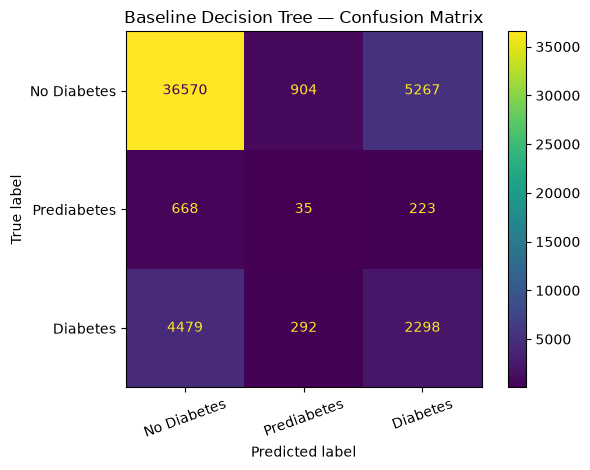

Confusion matrix:
[[36570   904  5267]
 [  668    35   223]
 [ 4479   292  2298]]


In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Compare actual categories with predicted categories
cm = confusion_matrix(y_test, y_pred, labels=[0.0, 1.0, 2.0])

# Display the confusion matrix
display_labels = ["No Diabetes", "Prediabetes", "Diabetes"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(values_format="d")
plt.title("Baseline Decision Tree — Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

3.6 Confusion Matrix Analysis

The confusion matrix provides further insight into the baseline Decision Tree's classification errors. The model correctly classified 36,570 No Diabetes cases, 35 Prediabetes cases, and 2,298 Diabetes cases.

The model performed poorly in identifying Prediabetes, correctly classifying only 35 of the 926 actual cases. It also misclassified 4,479 actual Diabetes cases as No Diabetes. These errors demonstrate that the model has difficulty identifying the minority classes.

The results suggest that the imbalanced target distribution may be contributing to the model's poor performance on Prediabetes and Diabetes. Consequently, the baseline model requires further investigation and improvement before it can be considered suitable for the intended screening and awareness purpose.

### 4. Improving the Model — Class Weighting

The baseline model performed poorly on the minority classes. In this experiment, a second Decision Tree will use balanced class weights to give greater importance to underrepresented categories during training.

The model will use the same training and testing split so that its results can be compared with the baseline. Its performance will be evaluated using accuracy, precision, recall, and F1-score.

In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create a new Decision Tree with balanced class weights
balanced_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

# Train the new model using only the training data
balanced_model.fit(X_train, y_train)

# Predict categories for the same held-out test set
y_pred_balanced = balanced_model.predict(X_test)

# Evaluate the new model
balanced_accuracy = accuracy_score(y_test, y_pred_balanced)

print(f"Balanced Decision Tree Test Accuracy: {balanced_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    labels=[0.0, 1.0, 2.0],
    target_names=["No Diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

Balanced Decision Tree Test Accuracy: 0.7637

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.87      0.86      0.86     42741
 Prediabetes       0.02      0.03      0.03       926
    Diabetes       0.28      0.29      0.28      7069

    accuracy                           0.76     50736
   macro avg       0.39      0.39      0.39     50736
weighted avg       0.77      0.76      0.77     50736



### 4.1 Results of the Class-Weighting Experiment

The Decision Tree trained with balanced class weights achieved a test accuracy of 76.37%, compared with 76.68% for the baseline model. The macro F1-score decreased from 0.40 to 0.39.

The F1-score for No Diabetes decreased from 0.87 to 0.86, while the Prediabetes F1-score remained at 0.03. The Diabetes F1-score decreased from 0.31 to 0.28.

Therefore, class weighting did not improve the overall reported metrics or the F1-scores for the minority classes in this experiment. The balanced model will be retained as a comparison, while further experiments will investigate whether limiting the tree's complexity improves generalisation.

### 4.2 Experiment — Limiting Tree Depth

A Decision Tree with unrestricted depth can learn highly detailed patterns from the training data, which may not generalise well to unseen observations.

In this experiment, the maximum tree depth is limited to 10. The model will use the same training and testing sets as the previous experiments. Its performance will be compared with the baseline and balanced models to determine whether limiting tree complexity is beneficial.

In [27]:
# Create a Decision Tree with a maximum depth of 10
limited_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

# Train the model
limited_model.fit(X_train, y_train)

# Predict the test categories
y_pred_limited = limited_model.predict(X_test)

# Evaluate the model
limited_accuracy = accuracy_score(y_test, y_pred_limited)

print(f"Limited-Depth Decision Tree Test Accuracy: {limited_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_limited,
    labels=[0.0, 1.0, 2.0],
    target_names=["No Diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

Limited-Depth Decision Tree Test Accuracy: 0.8453

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.86      0.97      0.91     42741
 Prediabetes       0.20      0.00      0.01       926
    Diabetes       0.51      0.20      0.29      7069

    accuracy                           0.85     50736
   macro avg       0.53      0.39      0.40     50736
weighted avg       0.80      0.85      0.81     50736



4.3 Results of the Limited-Depth Experiment

The Decision Tree with a maximum depth of 10 achieved a test accuracy of 84.53%, higher than the baseline model's 76.68% and the balanced model's 76.37%.

The No Diabetes F1-score increased to 0.91, while the Prediabetes F1-score decreased to 0.01. The Diabetes F1-score was 0.29, and the macro F1-score was 0.40.

Although limiting the tree depth improved overall accuracy, the model continued to perform poorly on Prediabetes and Diabetes. Its high accuracy therefore does not demonstrate that it is suitable for the intended health-screening purpose. Further evaluation should prioritise class-specific recall and F1-scores.

These results alone do not establish whether the original model was overfitting. A comparison of training and validation performance would be required to investigate that possibility.

In [28]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

models = {
    "Baseline": y_pred,
    "Balanced weights": y_pred_balanced,
    "Maximum depth 10": y_pred_limited
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Prediabetes Recall": recall_score(
            y_test, predictions, labels=[1.0],
            average="macro", zero_division=0
        ),
        "Diabetes Recall": recall_score(
            y_test, predictions, labels=[2.0],
            average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_test, predictions, average="macro",
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)
display(comparison_df.round(4))

,Model,Accuracy,Prediabetes Recall,Diabetes Recall,Macro F1-score
0,Baseline,0.7668,0.0378,0.3251,0.4026
1,Balanced weights,0.7637,0.0324,0.2880,0.3914
2,Maximum depth 10,0.8453,0.0032,0.1989,0.4024



## 8. Random Undersampling Experiment Using BRFSS 2015

### 8.1 Introduction

Previous experiments using the combined BRFSS 2015 and 2017 datasets revealed that class imbalance significantly affected the model's ability to identify prediabetes cases.

To investigate an alternative approach, we conduct a separate experiment using the original BRFSS 2015 dataset.

Random undersampling is a technique that reduces the number of observations in the majority class by randomly selecting a smaller subset of its records.

In this experiment, we focus on reducing the no-diabetes class while retaining the available prediabetes and diabetes records.

The objective is to investigate whether reducing the dominance of the majority class improves the model's ability to identify the minority classes.


In [29]:

# Step 46: Examine the original BRFSS 2015 class distribution.

print("BRFSS 2015 DATASET")
print("-" * 45)

print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(
    df["Diabetes_012"]
    .value_counts()
    .sort_index()
)

print("\nClass proportions:")
print(
    df["Diabetes_012"]
    .value_counts(normalize=True)
    .sort_index()
    .round(4)
)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())


BRFSS 2015 DATASET
---------------------------------------------
Dataset shape: (253680, 22)

Class distribution:
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

Class proportions:
Diabetes_012
0.0    0.8424
1.0    0.0183
2.0    0.1393
Name: proportion, dtype: float64

Training class distribution:
Diabetes_012
0.0    170962
1.0      3705
2.0     28277
Name: count, dtype: int64



### 8.2 Applying Random Undersampling

Three undersampling ratios are investigated: 10:1, 20:1, and 30:1, where the ratio represents the number of no-diabetes records retained for every prediabetes record.

All prediabetes and diabetes training records are retained. A random sample of no-diabetes records is selected for each experiment.

The random sampling is performed only on the training dataset. The original test dataset remains unchanged to ensure that model performance is evaluated using the original class distribution.

A fixed random seed of 42 is used to make the sampling process reproducible.


In [30]:
# Step 48: Apply random undersampling to the 2015 training data.

import pandas as pd

# Separate the three training classes.
X_no_diabetes = X_train[y_train == 0]
X_prediabetes = X_train[y_train == 1]
X_diabetes = X_train[y_train == 2]

y_no_diabetes = y_train[y_train == 0]
y_prediabetes = y_train[y_train == 1]
y_diabetes = y_train[y_train == 2]

# Define the undersampling ratios.
ratios = [10, 20, 30]

undersampled_datasets = {}

for ratio in ratios:

    # Calculate how many no-diabetes records to retain.
    sample_size = min(
        ratio * len(y_prediabetes),
        len(y_no_diabetes)
    )

    # Randomly select no-diabetes records.
    X_no_sample = X_no_diabetes.sample(
        n=sample_size,
        random_state=42
    )

    y_no_sample = y_no_diabetes.loc[X_no_sample.index]

    # Combine all three classes.
    X_resampled = pd.concat([
        X_no_sample,
        X_prediabetes,
        X_diabetes
    ])

    y_resampled = pd.concat([
        y_no_sample,
        y_prediabetes,
        y_diabetes
    ])

    # Shuffle the resulting training dataset.
    X_resampled = X_resampled.sample(
        frac=1,
        random_state=42
    )

    y_resampled = y_resampled.loc[X_resampled.index]

    undersampled_datasets[ratio] = (
        X_resampled,
        y_resampled
    )

    print(f"\nUNDERSAMPLING RATIO: {ratio}:1")
    print("-" * 40)
    print(y_resampled.value_counts().sort_index())
    print("Total records:", len(y_resampled))


UNDERSAMPLING RATIO: 10:1
----------------------------------------
Diabetes_012
0.0    37050
1.0     3705
2.0    28277
Name: count, dtype: int64
Total records: 69032

UNDERSAMPLING RATIO: 20:1
----------------------------------------
Diabetes_012
0.0    74100
1.0     3705
2.0    28277
Name: count, dtype: int64
Total records: 106082

UNDERSAMPLING RATIO: 30:1
----------------------------------------
Diabetes_012
0.0    111150
1.0      3705
2.0     28277
Name: count, dtype: int64
Total records: 143132



### 8.3 Training Decision Trees on Undersampled Data

Three Decision Tree classifiers are trained using the undersampled datasets created with ratios of 10:1, 20:1, and 30:1.

All models use the same Decision Tree configuration and random state to make the comparison consistent.

The original 2015 test dataset is retained without undersampling. This ensures that each model is evaluated against the same class distribution.

The evaluation uses accuracy, macro F1-score, class-specific precision and recall, and confusion matrices.


In [31]:
# Step 50: Train and evaluate undersampled Decision Trees.

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

undersampling_results = []

undersampled_models = {}

for ratio, (X_resampled, y_resampled) in undersampled_datasets.items():

    # Create and train the Decision Tree.
    model = DecisionTreeClassifier(random_state=42)

    model.fit(X_resampled, y_resampled)

    # Predict using the original, unchanged test data.
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics.
    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    undersampling_results.append({
        "Ratio": f"{ratio}:1",
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    undersampled_models[ratio] = model

    print(f"\nUNDERSAMPLING RATIO: {ratio}:1")
    print("=" * 55)

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=[
            "No diabetes",
            "Prediabetes",
            "Diabetes"
        ],
        digits=4,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1, 2]
    ))

print("\nUNDERSAMPLING MODEL SUMMARY")
display(
    pd.DataFrame(undersampling_results).round(4)
)


UNDERSAMPLING RATIO: 10:1
Accuracy: 0.6458
Macro F1: 0.3861

Classification Report:
              precision    recall  f1-score   support

 No diabetes     0.9064    0.6713    0.7713     42741
 Prediabetes     0.0275    0.0896    0.0421       926
    Diabetes     0.2484    0.5644    0.3450      7069

    accuracy                         0.6458     50736
   macro avg     0.3941    0.4418    0.3861     50736
weighted avg     0.7987    0.6458    0.6986     50736

Confusion Matrix:
[[28693  2416 11632]
 [  405    83   438]
 [ 2558   521  3990]]

UNDERSAMPLING RATIO: 20:1
Accuracy: 0.7097
Macro F1: 0.3995

Classification Report:
              precision    recall  f1-score   support

 No diabetes     0.8909    0.7661    0.8238     42741
 Prediabetes     0.0271    0.0594    0.0372       926
    Diabetes     0.2684    0.4540    0.3374      7069

    accuracy                         0.7097     50736
   macro avg     0.3955    0.4265    0.3995     50736
weighted avg     0.7884    0.7097    0.74

,Ratio,Accuracy,Macro F1
0,10:1,0.6458,0.3861
1,20:1,0.7097,0.3995
2,30:1,0.7392,0.4057



### 8.4 Detailed Comparison of Undersampling Models

The three undersampled Decision Trees are compared using class-specific precision, recall and F1-scores.

This comparison helps determine whether improvements in overall performance also translate into better identification of prediabetes and diabetes cases.


In [32]:

# Step 52: Retrieve complete class-specific evaluation metrics.

from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

detailed_undersampling_results = []

for ratio, model in undersampled_models.items():

    predictions = model.predict(X_test)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        predictions,
        labels=[0, 1, 2],
        zero_division=0
    )

    for i, class_name in enumerate(
        ["No diabetes", "Prediabetes", "Diabetes"]
    ):
        detailed_undersampling_results.append({
            "Ratio": f"{ratio}:1",
            "Class": class_name,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1-score": f1[i],
            "Support": support[i]
        })

display(
    pd.DataFrame(detailed_undersampling_results).round(4)
)


,Ratio,Class,Precision,Recall,F1-score,Support
0,10:1,No diabetes,0.9064,0.6713,0.7713,42741
1,10:1,Prediabetes,0.0275,0.0896,0.0421,926
2,10:1,Diabetes,0.2484,0.5644,0.3450,7069
3,20:1,No diabetes,0.8909,0.7661,0.8238,42741
4,20:1,Prediabetes,0.0271,0.0594,0.0372,926
5,20:1,Diabetes,0.2684,0.4540,0.3374,7069
6,30:1,No diabetes,0.8840,0.8111,0.8460,42741
7,30:1,Prediabetes,0.0328,0.0594,0.0422,926
8,30:1,Diabetes,0.2825,0.3933,0.3288,7069



### 8.5 Discussion of Random Undersampling Results

#### Results
Three undersampling configurations were evaluated using Decision Tree classifiers: 10:1, 20:1, and 30:1.

The 10:1 configuration achieved a prediabetes recall of 8.96%, compared with 5.94% for both the 20:1 and 30:1 configurations. However, it had the lowest accuracy (64.58%) and macro F1-score (0.3861).

The 30:1 configuration achieved the highest accuracy (73.92%) and macro F1-score (0.4057). It also achieved the highest prediabetes precision (3.28%).

#### Comparison with the Original Baseline
The original 2015 Decision Tree achieved an accuracy of 76.68%, macro F1-score of 0.4026, and prediabetes recall of 3.78%.

All three undersampled models improved prediabetes recall compared with the original baseline. The 30:1 configuration also achieved a slightly higher macro F1-score, although its accuracy was lower.

#### Interpretation
Random undersampling improved the identification of prediabetes cases, but the resulting precision remained low. The 10:1 configuration favoured minority-class recall, whereas the 30:1 configuration achieved better overall classification balance.

#### Conclusion
Random undersampling demonstrated potential for improving minority-class detection in the BRFSS 2015 dataset. Among the tested configurations, 30:1 achieved the highest macro F1-score, while 10:1 achieved the highest prediabetes recall.

No configuration can yet be considered suitable for the intended screening purpose because prediabetes precision remains very low. Further experiments are required to investigate whether combining undersampling with other classification approaches can improve performance.



### 8.6 Random Forest Evaluation on Undersampled BRFSS 2015 Data

#### Objective
To investigate whether Random Forest classifiers trained on undersampled BRFSS 2015 data improve classification performance compared with the undersampled Decision Trees.

#### Methodology
Random Forest classifiers containing 100 trees are trained using the three undersampled training datasets. The models are evaluated on the same original, unchanged test dataset.

Accuracy, macro F1-score, class-specific precision and recall, and confusion matrices are used to assess performance.


In [33]:
# Step 55: Train Random Forest models on undersampled 2015 data.

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

rf_undersampling_results = []
rf_undersampled_models = {}

for ratio, (X_resampled, y_resampled) in undersampled_datasets.items():

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_resampled, y_resampled)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    rf_undersampling_results.append({
        "Ratio": f"{ratio}:1",
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    rf_undersampled_models[ratio] = model

    print(f"\nRANDOM FOREST - UNDERSAMPLING {ratio}:1")
    print("=" * 55)

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=[
            "No diabetes",
            "Prediabetes",
            "Diabetes"
        ],
        digits=4,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1, 2]
    ))

print("\nRANDOM FOREST UNDERSAMPLING SUMMARY")

display(
    pd.DataFrame(rf_undersampling_results).round(4)
)


RANDOM FOREST - UNDERSAMPLING 10:1
Accuracy: 0.7362
Macro F1: 0.4248

Classification Report:
              precision    recall  f1-score   support

 No diabetes     0.9301    0.7566    0.8344     42741
 Prediabetes     0.0072    0.0011    0.0019       926
    Diabetes     0.3169    0.7097    0.4381      7069

    accuracy                         0.7362     50736
   macro avg     0.4181    0.4891    0.4248     50736
weighted avg     0.8278    0.7362    0.7640     50736

Confusion Matrix:
[[32336   118 10287]
 [  396     1   529]
 [ 2033    19  5017]]

RANDOM FOREST - UNDERSAMPLING 20:1
Accuracy: 0.8087
Macro F1: 0.4396

Classification Report:
              precision    recall  f1-score   support

 No diabetes     0.8982    0.8805    0.8892     42741
 Prediabetes     0.0000    0.0000    0.0000       926
    Diabetes     0.3884    0.4807    0.4296      7069

    accuracy                         0.8087     50736
   macro avg     0.4289    0.4537    0.4396     50736
weighted avg     0.8108

,Ratio,Accuracy,Macro F1
0,10:1,0.7362,0.4248
1,20:1,0.8087,0.4396
2,30:1,0.8319,0.4300



### 8.7 Detailed Evaluation of Random Forest Undersampling Models

The Random Forest models trained using the 10:1, 20:1, and 30:1 undersampling configurations are compared using class-specific precision, recall, and F1-scores.

This evaluation helps establish whether the improvement in overall performance is accompanied by better identification of prediabetes and diabetes cases.


In [34]:
# Step 57: Retrieve complete Random Forest class-specific metrics.

from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

rf_detailed_results = []

for ratio, model in rf_undersampled_models.items():

    predictions = model.predict(X_test)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        predictions,
        labels=[0, 1, 2],
        zero_division=0
    )

    for i, class_name in enumerate(
        ["No diabetes", "Prediabetes", "Diabetes"]
    ):
        rf_detailed_results.append({
            "Ratio": f"{ratio}:1",
            "Class": class_name,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1-score": f1[i],
            "Support": support[i]
        })

display(
    pd.DataFrame(rf_detailed_results).round(4)
)

,Ratio,Class,Precision,Recall,F1-score,Support
0,10:1,No diabetes,0.9301,0.7566,0.8344,42741
1,10:1,Prediabetes,0.0072,0.0011,0.0019,926
2,10:1,Diabetes,0.3169,0.7097,0.4381,7069
3,20:1,No diabetes,0.8982,0.8805,0.8892,42741
4,20:1,Prediabetes,0.0000,0.0000,0.0000,926
5,20:1,Diabetes,0.3884,0.4807,0.4296,7069
6,30:1,No diabetes,0.8810,0.9309,0.9053,42741
7,30:1,Prediabetes,0.0000,0.0000,0.0000,926
8,30:1,Diabetes,0.4388,0.3426,0.3848,7069


### 8.6 Comparison of Decision Tree and Random Forest Undersampling

The results show that Random Forest achieved higher accuracy and macro F1
scores than Decision Tree across all three undersampling ratios.

However, Decision Tree achieved higher recall for the prediabetes class
across all ratios. Random Forest recorded almost zero prediabetes recall,
meaning it failed to identify most actual prediabetes cases.

The 10:1 Decision Tree achieved the highest prediabetes recall of 8.96%
among the six undersampling experiments. Although this is an improvement
over the original 2015 Decision Tree baseline of 3.78%, the result remains
low.

Therefore, Random Forest's higher overall performance does not necessarily
make it the better model for HealthAware. Model selection must consider
the ability to identify each diabetes-related category, particularly
prediabetes, rather than relying on accuracy or macro F1 alone.

Random undersampling improved some class-specific results but did not
adequately address the prediabetes classification challenge.

### 8.7 SMOTE Oversampling Experiment

SMOTE is an oversampling technique that generates synthetic observations
for minority classes.

In this experiment, SMOTE will be applied only to the training data to
avoid data leakage. The original test dataset will remain unchanged so
that the models are evaluated against the original class distribution.

The experiment will investigate whether increasing minority-class
representation improves the classification of prediabetes and diabetes.

#### Installing the imbalanced-learn library

The imbalanced-learn library provides SMOTE and other techniques for
handling imbalanced datasets. It must be installed before importing SMOTE.

In [35]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [36]:
# Import SMOTE
from imblearn.over_sampling import SMOTE

print("SMOTE imported successfully.")

SMOTE imported successfully.


#### Applying SMOTE to the training dataset

SMOTE generates synthetic observations for minority classes by interpolating
between existing minority-class observations.

We will apply it to the training dataset only. The test dataset will retain
its original class distribution to provide a consistent evaluation basis.

The default sampling strategy will oversample minority classes until they
match the majority class.

In [4]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to training data only
smote = SMOTE(random_state=42, k_neighbors=5)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

print("Original training distribution:")
print(y_train.value_counts().sort_index())

print("\nSMOTE training distribution:")
print(y_train_smote.value_counts().sort_index())

print("\nOriginal training shape:", X_train.shape)
print("SMOTE training shape:", X_train_smote.shape)

print("\nTest distribution (unchanged):")
print(y_test.value_counts().sort_index())

NameError: name 'X_train' is not defined

#### Recreating the original 2015 training and test datasets

The current notebook session does not contain the original training and
test variables. We will recreate the stratified 80:20 split from the
original BRFSS 2015 dataframe.

The random state will remain 42 to ensure reproducibility. Stratification
will preserve the original class proportions in both datasets.

In [5]:
from sklearn.model_selection import train_test_split

# Separate features and target from the original 2015 dataset
X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"]

# Recreate the original stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

NameError: name 'df' is not defined

#### Loading the original BRFSS 2015 dataset

The current notebook session does not contain the original dataframe.
We will load the original 2015 CSV file before recreating the stratified
training and testing datasets.

This experiment will use the original dataset, not the previously
undersampled datasets.

In [6]:
import pandas as pd

# Load the original BRFSS 2015 dataset
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["Diabetes_012"].value_counts().sort_index())

FileNotFoundError: [Errno 2] No such file or directory: 'diabetes_012_health_indicators_BRFSS2015.csv'

#### Locating the original BRFSS 2015 dataset

Before loading the dataset, we will inspect the notebook's current
working directory and search for the original CSV file.

This ensures that we use the same dataset as our previous experiments.

In [37]:
from pathlib import Path

# Display the current working directory
current_directory = Path.cwd()

print("Current working directory:")
print(current_directory)

# Search the project directory and its subdirectories
csv_files = list(
    current_directory.rglob("diabetes_012_health_indicators_BRFSS2015.csv")
)

print("\nMatching CSV files:")

if csv_files:
    for file in csv_files:
        print(file)
else:
    print("The CSV was not found inside this project directory.")

Current working directory:
c:\Users\USER\Desktop\projects\AI project\SemProject_MLEngine

Matching CSV files:
c:\Users\USER\Desktop\projects\AI project\SemProject_MLEngine\data\diabetes_012_health_indicators_BRFSS2015.csv


#### Loading the original BRFSS 2015 dataset

The original CSV file is located in the project's `data` directory.
We will load it using its relative path and verify its dimensions and
target class distribution before recreating the train/test split.

In [38]:
import pandas as pd

# Load the original 2015 dataset
df = pd.read_csv(
    "data/diabetes_012_health_indicators_BRFSS2015.csv"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["Diabetes_012"].value_counts().sort_index())

Dataset loaded successfully.
Dataset shape: (253680, 22)

Target distribution:
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


#### Preparing the training and testing datasets

The dataset is divided into 80% training data and 20% testing data.
Stratified sampling is used to preserve the original class proportions.

The training data will be used for SMOTE and model training. The original
testing data will remain unchanged and will only be used for evaluation.

In [39]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"]

# Stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training shape: (202944, 21)
Testing shape: (50736, 21)

Training class distribution:
Diabetes_012
0.0    170962
1.0      3705
2.0     28277
Name: count, dtype: int64

Testing class distribution:
Diabetes_012
0.0    42741
1.0      926
2.0     7069
Name: count, dtype: int64


#### Preparing categorical features for SMOTENC

SMOTENC is selected because the BRFSS dataset contains a mixture of
numerical, binary and ordinal categorical variables.

The categorical feature indices will be identified from the training
data's column positions. The target variable, Diabetes_012, will not
be included among the input features.

SMOTENC will be fitted only on the training data. The original test
dataset will remain unchanged.

In [40]:
from imblearn.over_sampling import SMOTENC

# Identify categorical features
categorical_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income"
]

# Convert categorical column names to their positional indices
categorical_indices = [
    X_train.columns.get_loc(column)
    for column in categorical_features
]

print("Total input features:", len(X_train.columns))
print("Categorical features:", len(categorical_features))
print("Numerical features:",
      len(X_train.columns) - len(categorical_features))

print("\nCategorical feature indices:")
print(categorical_indices)

print("\nCategorical feature names:")
print(categorical_features)

Total input features: 21
Categorical features: 18
Numerical features: 3

Categorical feature indices:
[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 16, 17, 18, 19, 20]

Categorical feature names:
['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


#### Applying SMOTENC to the training dataset

SMOTENC is applied to the original training data using the identified
categorical feature indices.

The method generates synthetic observations for the minority classes
while respecting the categorical nature of the specified features.

The test dataset is not resampled. This allows the models to be evaluated
using the original class distribution.

In [41]:
from imblearn.over_sampling import SMOTENC

# Initialize SMOTENC
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42,
    k_neighbors=5
)

# Resample training data only
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(
    X_train,
    y_train
)

print("Original training distribution:")
print(y_train.value_counts().sort_index())

print("\nSMOTENC training distribution:")
print(y_train_smotenc.value_counts().sort_index())

print("\nOriginal training shape:", X_train.shape)
print("SMOTENC training shape:", X_train_smotenc.shape)

print("\nTest distribution (unchanged):")
print(y_test.value_counts().sort_index())

Original training distribution:
Diabetes_012
0.0    170962
1.0      3705
2.0     28277
Name: count, dtype: int64

SMOTENC training distribution:
Diabetes_012
0.0    170962
1.0    170962
2.0    170962
Name: count, dtype: int64

Original training shape: (202944, 21)
SMOTENC training shape: (512886, 21)

Test distribution (unchanged):
Diabetes_012
0.0    42741
1.0      926
2.0     7069
Name: count, dtype: int64


#### Validating SMOTENC-generated observations

After resampling, we inspect the categorical features to determine
whether their generated values belong to the valid categories observed
in the original training dataset.

We also inspect the numerical features for unexpected values.

This check helps identify potential data-quality problems introduced
during synthetic data generation.

In [42]:
# Check categorical values against the original training categories
categorical_validation = {}

for column in categorical_features:
    original_values = set(X_train[column].unique())
    generated_values = set(X_train_smotenc[column].unique())

    invalid_values = generated_values - original_values

    categorical_validation[column] = {
        "Invalid values": list(invalid_values),
        "Valid": len(invalid_values) == 0
    }

categorical_validation_df = pd.DataFrame(
    categorical_validation
).T

print("Categorical feature validation:")
display(categorical_validation_df)

# Inspect numerical feature ranges
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

print("\nNumerical feature ranges:")
display(
    pd.DataFrame({
        "Original minimum": X_train[numerical_features].min(),
        "Original maximum": X_train[numerical_features].max(),
        "SMOTENC minimum": X_train_smotenc[numerical_features].min(),
        "SMOTENC maximum": X_train_smotenc[numerical_features].max()
    })
)

Categorical feature validation:


,Invalid values,Valid
HighBP,[],True
HighChol,[],True
CholCheck,[],True
Smoker,[],True
Stroke,[],True
HeartDiseaseorAttack,[],True
PhysActivity,[],True
Fruits,[],True
Veggies,[],True
HvyAlcoholConsump,[],True



Numerical feature ranges:


,Original minimum,Original maximum,SMOTENC minimum,SMOTENC maximum
BMI,12.0,98.0,12.0,98.0
MentHlth,0.0,30.0,0.0,30.0
PhysHlth,0.0,30.0,0.0,30.0


#### Training a Decision Tree using SMOTENC

A Decision Tree classifier is trained using the SMOTENC-resampled
training dataset.

The model uses the same random state as the earlier baseline model
to maintain consistency.

Evaluation is performed on the original test dataset, which retains
the natural class imbalance.

Performance will be measured using accuracy, macro F1-score,
class-specific precision and recall, and a confusion matrix.

In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Initialize and train Decision Tree
dt_smotenc = DecisionTreeClassifier(random_state=42)

dt_smotenc.fit(X_train_smotenc, y_train_smotenc)

# Predict on original test data
dt_smotenc_predictions = dt_smotenc.predict(X_test)

# Evaluate
print("SMOTENC DECISION TREE RESULTS")
print("Accuracy:",
      round(accuracy_score(y_test, dt_smotenc_predictions), 4))

print("Macro F1:",
      round(f1_score(
          y_test,
          dt_smotenc_predictions,
          average="macro"
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_smotenc_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_smotenc_predictions))

SMOTENC DECISION TREE RESULTS
Accuracy: 0.7418
Macro F1: 0.4035

Classification Report:
              precision    recall  f1-score   support

 No diabetes       0.88      0.82      0.85     42741
 Prediabetes       0.03      0.06      0.04       926
    Diabetes       0.29      0.37      0.32      7069

    accuracy                           0.74     50736
   macro avg       0.40      0.42      0.40     50736
weighted avg       0.78      0.74      0.76     50736


Confusion Matrix:
[[34990  1613  6138]
 [  620    58   248]
 [ 4011   468  2590]]


#### SMOTENC Decision Tree Evaluation

The Decision Tree trained using SMOTENC achieved an accuracy of 74.18%
and a macro F1-score of 0.4035.

Prediabetes recall increased from 3.78% in the original baseline to
6.26%, identifying 58 out of 926 actual prediabetes cases.

However, the model still failed to identify most prediabetes cases.
It also generated a substantial number of false prediabetes predictions.

Compared with random undersampling, SMOTENC produced a slightly higher
macro F1-score than the 10:1 and 20:1 experiments, but lower than the
30:1 experiment.

These findings suggest that balancing the training dataset alone does
not adequately resolve the difficulty of classifying prediabetes.
Further model comparisons are required.

#### Random Forest using SMOTENC

A Random Forest classifier is trained using the SMOTENC-resampled
training dataset.

The model combines predictions from multiple decision trees to
improve classification performance.

The model is evaluated against the original, unchanged test dataset
using accuracy, macro F1-score, class-specific precision and recall,
and a confusion matrix.

In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Initialize Random Forest
rf_smotenc = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train using SMOTENC data
rf_smotenc.fit(X_train_smotenc, y_train_smotenc)

# Predict on the original test set
rf_smotenc_predictions = rf_smotenc.predict(X_test)

# Evaluate
print("SMOTENC RANDOM FOREST RESULTS")

print("Accuracy:",
      round(accuracy_score(y_test, rf_smotenc_predictions), 4))

print("Macro F1:",
      round(f1_score(
          y_test,
          rf_smotenc_predictions,
          average="macro"
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_smotenc_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_smotenc_predictions))

SMOTENC RANDOM FOREST RESULTS
Accuracy: 0.7967
Macro F1: 0.4409

Classification Report:
              precision    recall  f1-score   support

 No diabetes       0.90      0.87      0.88     42741
 Prediabetes       0.03      0.03      0.03       926
    Diabetes       0.38      0.45      0.41      7069

    accuracy                           0.80     50736
   macro avg       0.43      0.45      0.44     50736
weighted avg       0.81      0.80      0.80     50736


Confusion Matrix:
[[37206   588  4947]
 [  598    24   304]
 [ 3718   162  3189]]



## Comparison of Models and Class Imbalance Handling Techniques

This section compares the Decision Tree and Random Forest models trained using different approaches to address class imbalance.

The experiments include:
- Original training data without resampling.
- Random undersampling at 10:1, 20:1 and 30:1 class ratios.
- SMOTENC oversampling.

The models are evaluated using accuracy, macro F1-score and prediabetes recall.

Macro F1 is important because it gives equal importance to each class, while prediabetes recall shows how effectively the model identifies actual prediabetes cases.

The comparison will help determine which modelling approach provides the most appropriate balance of classification performance across the three classes.


In [46]:
%pip install jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)

   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]

Note: you may need to restart the kernel to use updated packages.


In [47]:

import pandas as pd

results = [
    {
        "Model": "Decision Tree - Original",
        "Technique": "No resampling",
        "Accuracy": 0.7668,
        "Macro F1": 0.4026,
        "Prediabetes Recall": 0.0378
    },
    {
        "Model": "Decision Tree - 10:1",
        "Technique": "Random Undersampling",
        "Accuracy": 0.6458,
        "Macro F1": 0.3861,
        "Prediabetes Recall": 0.0896
    },
    {
        "Model": "Decision Tree - 20:1",
        "Technique": "Random Undersampling",
        "Accuracy": 0.7097,
        "Macro F1": 0.3995,
        "Prediabetes Recall": 0.0594
    },
    {
        "Model": "Decision Tree - 30:1",
        "Technique": "Random Undersampling",
        "Accuracy": 0.7392,
        "Macro F1": 0.4057,
        "Prediabetes Recall": 0.0594
    },
    {
        "Model": "Random Forest - 10:1",
        "Technique": "Random Undersampling",
        "Accuracy": 0.7362,
        "Macro F1": 0.4248,
        "Prediabetes Recall": 0.0011
    },
    {
        "Model": "Random Forest - 20:1",
        "Technique": "Random Undersampling",
        "Accuracy": 0.8087,
        "Macro F1": 0.4396,
        "Prediabetes Recall": 0.0000
    },
    {
        "Model": "Random Forest - 30:1",
        "Technique": "Random Undersampling",
        "Accuracy": 0.8319,
        "Macro F1": 0.4300,
        "Prediabetes Recall": 0.0000
    },
    {
        "Model": "Decision Tree - SMOTENC",
        "Technique": "SMOTENC Oversampling",
        "Accuracy": 0.7418,
        "Macro F1": 0.4035,
        "Prediabetes Recall": 0.0626
    },
    {
        "Model": "Random Forest - SMOTENC",
        "Technique": "SMOTENC Oversampling",
        "Accuracy": 0.7967,
        "Macro F1": 0.4409,
        "Prediabetes Recall": 0.0259
    }
]

comparison_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Prediabetes Recall": "{:.4f}"
    }).highlight_max(
        subset=["Accuracy", "Macro F1", "Prediabetes Recall"],
        color="lightgreen"
    )
)


MODEL PERFORMANCE COMPARISON


,Model,Technique,Accuracy,Macro F1,Prediabetes Recall
0,Decision Tree - Original,No resampling,0.7668,0.4026,0.0378
1,Decision Tree - 10:1,Random Undersampling,0.6458,0.3861,0.0896
2,Decision Tree - 20:1,Random Undersampling,0.7097,0.3995,0.0594
3,Decision Tree - 30:1,Random Undersampling,0.7392,0.4057,0.0594
4,Random Forest - 10:1,Random Undersampling,0.7362,0.4248,0.0011
5,Random Forest - 20:1,Random Undersampling,0.8087,0.4396,0.0000
6,Random Forest - 30:1,Random Undersampling,0.8319,0.4300,0.0000
7,Decision Tree - SMOTENC,SMOTENC Oversampling,0.7418,0.4035,0.0626
8,Random Forest - SMOTENC,SMOTENC Oversampling,0.7967,0.4409,0.0259



## Preliminary Model Selection

The experimental results are compared using accuracy, macro F1-score and prediabetes recall.

The Random Forest model trained using SMOTENC achieved the highest macro F1-score of 0.4409. It is therefore the strongest candidate based on overall class-balanced performance among the experiments conducted.

However, its prediabetes recall was only 0.0259, meaning that it correctly identified very few actual prediabetes cases.

The Decision Tree trained using 10:1 random undersampling achieved the highest prediabetes recall of 0.0896, although its overall macro F1-score was lower.

The results demonstrate a trade-off between overall classification performance and identifying the minority prediabetes class. Further validation and model comparison are necessary before selecting the final model.



## Cross-Validation of the SMOTENC Random Forest Model

Stratified 5-Fold Cross-Validation will be used to evaluate the consistency of the selected Random Forest model.

The training data will be divided into five folds. In each iteration, four folds will be used for training and the remaining fold will be used for validation.

SMOTENC will be applied only to the training portion of each fold to prevent data leakage. The validation fold will retain its original class distribution.

Macro F1-score will be used as the primary evaluation metric because the dataset contains imbalanced classes.


In [48]:

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import make_scorer, f1_score

# Define stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Check class distribution in the current training data
print("Training data shape:", X_train.shape)
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nNumber of categorical features:", len(categorical_indices))
print("Number of cross-validation folds:", cv.get_n_splits())


Training data shape: (202944, 21)

Training class distribution:
Diabetes_012
0.0    170962
1.0      3705
2.0     28277
Name: count, dtype: int64

Number of categorical features: 18
Number of cross-validation folds: 5



## Building the Cross-Validation Pipeline

An imbalanced-learn pipeline will combine SMOTENC and Random Forest.

During each cross-validation iteration, SMOTENC will generate synthetic minority-class samples using only the training fold. Random Forest will then learn from the resampled data.

The validation fold will not undergo oversampling. This ensures that evaluation reflects the original class distribution and prevents data leakage.


In [49]:

# Create the SMOTENC and Random Forest pipeline

rf_smotenc_pipeline = ImbPipeline(steps=[
    (
        "smotenc",
        SMOTENC(
            categorical_features=categorical_indices,
            random_state=42,
            k_neighbors=5
        )
    ),
    (
        "random_forest",
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("SMOTENC Random Forest pipeline created successfully.")

print("\nPipeline steps:")
for step_name, estimator in rf_smotenc_pipeline.steps:
    print(f"{step_name}: {estimator}")


SMOTENC Random Forest pipeline created successfully.

Pipeline steps:
smotenc: SMOTENC(categorical_features=[0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 16, 17,
                              18, 19, 20],
        random_state=42)
random_forest: RandomForestClassifier(n_jobs=-1, random_state=42)



## Performing Stratified 5-Fold Cross-Validation

The SMOTENC Random Forest pipeline will be evaluated using stratified 5-fold cross-validation.

Macro F1-score is the primary evaluation metric because it gives equal importance to all three diabetes-related classes.

Accuracy will also be measured to provide an additional view of overall classification performance.

The mean and standard deviation across the five folds will be examined to assess the model's average performance and consistency.


In [50]:

from sklearn.model_selection import cross_validate

scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy"
}

cv_results = cross_validate(
    rf_smotenc_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False,
    verbose=2
)

print("\nSMOTENC RANDOM FOREST - 5-FOLD CROSS-VALIDATION")

for fold in range(5):
    print(
        f"Fold {fold + 1}: "
        f"Macro F1 = {cv_results['test_macro_f1'][fold]:.4f}, "
        f"Accuracy = {cv_results['test_accuracy'][fold]:.4f}"
    )

print("\nAVERAGE PERFORMANCE")
print("Mean Macro F1:",
      round(cv_results["test_macro_f1"].mean(), 4))
print("Macro F1 Standard Deviation:",
      round(cv_results["test_macro_f1"].std(), 4))

print("Mean Accuracy:",
      round(cv_results["test_accuracy"].mean(), 4))
print("Accuracy Standard Deviation:",
      round(cv_results["test_accuracy"].std(), 4))


[CV] END .................................................... total time= 1.8min
[CV] END .................................................... total time= 1.6min
[CV] END .................................................... total time= 1.7min
[CV] END .................................................... total time= 1.7min
[CV] END .................................................... total time= 1.7min

SMOTENC RANDOM FOREST - 5-FOLD CROSS-VALIDATION
Fold 1: Macro F1 = 0.4434, Accuracy = 0.7977
Fold 2: Macro F1 = 0.4412, Accuracy = 0.7990
Fold 3: Macro F1 = 0.4391, Accuracy = 0.7970
Fold 4: Macro F1 = 0.4453, Accuracy = 0.7958
Fold 5: Macro F1 = 0.4332, Accuracy = 0.7950

AVERAGE PERFORMANCE
Mean Macro F1: 0.4404
Macro F1 Standard Deviation: 0.0042
Mean Accuracy: 0.7969
Accuracy Standard Deviation: 0.0014


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  8.5min finished



## Class-Level Evaluation Using Cross-Validated Predictions

Overall evaluation metrics may hide poor performance in individual classes.

Cross-validated predictions will therefore be used to examine precision, recall and F1-score for each class.

This analysis will help determine whether the model performs consistently across the three diabetes-related categories, particularly the minority prediabetes class.


In [51]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Generate out-of-fold predictions
cv_predictions = cross_val_predict(
    rf_smotenc_pipeline,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1,
    method="predict",
    verbose=2
)

print("CROSS-VALIDATED CLASSIFICATION REPORT")

print(classification_report(
    y_train,
    cv_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

print("CROSS-VALIDATED CONFUSION MATRIX")

print(confusion_matrix(y_train, cv_predictions))


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed: 10.4min finished


CROSS-VALIDATED CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No diabetes       0.90      0.87      0.88    170962
 Prediabetes       0.03      0.02      0.03      3705
    Diabetes       0.38      0.45      0.41     28277

    accuracy                           0.80    202944
   macro avg       0.43      0.45      0.44    202944
weighted avg       0.81      0.80      0.80    202944

CROSS-VALIDATED CONFUSION MATRIX
[[148789   2184  19989]
 [  2502     84   1119]
 [ 14805    616  12856]]



## Investigating Class Weighting

Class weighting is another approach for handling imbalanced classification datasets.

The Random Forest classifier supports class weighting, which assigns greater importance to classes with fewer training examples.

The balanced weighting strategy automatically calculates weights based on class frequencies.

This experiment will investigate whether class weighting improves the model's ability to identify the minority prediabetes class without generating synthetic samples.


In [52]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

balanced_scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy"
}

balanced_cv_results = cross_validate(
    rf_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring=balanced_scoring,
    n_jobs=1,
    return_train_score=False,
    verbose=2
)

print("\nBALANCED RANDOM FOREST - 5-FOLD CROSS-VALIDATION")

for fold in range(5):
    print(
        f"Fold {fold + 1}: "
        f"Macro F1 = {balanced_cv_results['test_macro_f1'][fold]:.4f}, "
        f"Accuracy = {balanced_cv_results['test_accuracy'][fold]:.4f}"
    )

print("\nAVERAGE PERFORMANCE")
print("Mean Macro F1:",
      round(balanced_cv_results["test_macro_f1"].mean(), 4))

print("Macro F1 Standard Deviation:",
      round(balanced_cv_results["test_macro_f1"].std(), 4))

print("Mean Accuracy:",
      round(balanced_cv_results["test_accuracy"].mean(), 4))


[CV] END .................................................... total time=   5.0s
[CV] END .................................................... total time=   5.0s
[CV] END .................................................... total time=   4.9s
[CV] END .................................................... total time=   5.0s
[CV] END .................................................... total time=   5.0s

BALANCED RANDOM FOREST - 5-FOLD CROSS-VALIDATION
Fold 1: Macro F1 = 0.4427, Accuracy = 0.7921
Fold 2: Macro F1 = 0.4424, Accuracy = 0.7921
Fold 3: Macro F1 = 0.4418, Accuracy = 0.7914
Fold 4: Macro F1 = 0.4434, Accuracy = 0.7929
Fold 5: Macro F1 = 0.4366, Accuracy = 0.7898

AVERAGE PERFORMANCE
Mean Macro F1: 0.4414
Macro F1 Standard Deviation: 0.0024
Mean Accuracy: 0.7917


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   25.5s finished



## Class-Level Evaluation of the Balanced Random Forest

The balanced Random Forest will be evaluated using cross-validated predictions.

Precision, recall and F1-score will be examined for each class to determine whether automatic class weighting improves the identification of minority-class records.

The results will also be compared with the SMOTENC Random Forest cross-validation results.


In [53]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Generate out-of-fold predictions
balanced_cv_predictions = cross_val_predict(
    rf_balanced,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1,
    method="predict",
    verbose=2
)

print("BALANCED RANDOM FOREST - CLASSIFICATION REPORT")

print(classification_report(
    y_train,
    balanced_cv_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

print("BALANCED RANDOM FOREST - CONFUSION MATRIX")

print(confusion_matrix(y_train, balanced_cv_predictions))


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   30.9s finished


BALANCED RANDOM FOREST - CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No diabetes       0.91      0.85      0.88    170962
 Prediabetes       0.02      0.01      0.01      3705
    Diabetes       0.37      0.54      0.44     28277

    accuracy                           0.79    202944
   macro avg       0.43      0.47      0.44    202944
weighted avg       0.82      0.79      0.80    202944

BALANCED RANDOM FOREST - CONFUSION MATRIX
[[145304    807  24851]
 [  2249     19   1437]
 [ 12800    135  15342]]



## Cross-Validation of the SMOTENC Decision Tree

The SMOTENC Decision Tree will be evaluated using stratified 5-fold cross-validation.

An imbalanced-learn pipeline will ensure that SMOTENC is applied only to the training portion of each fold.

The evaluation will use macro F1-score and accuracy, followed by class-level precision, recall and F1-score.

The results will be compared with the SMOTENC Random Forest to examine the trade-off between overall performance and prediabetes detection.


In [54]:

from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import cross_validate

dt_smotenc_pipeline = ImbPipeline(steps=[
    (
        "smotenc",
        SMOTENC(
            categorical_features=categorical_indices,
            random_state=42,
            k_neighbors=5
        )
    ),
    (
        "decision_tree",
        DecisionTreeClassifier(random_state=42)
    )
])

dt_smotenc_cv_results = cross_validate(
    dt_smotenc_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=1,
    return_train_score=False,
    verbose=2
)

print("\nSMOTENC DECISION TREE - 5-FOLD CROSS-VALIDATION")

for fold in range(5):
    print(
        f"Fold {fold + 1}: "
        f"Macro F1 = {dt_smotenc_cv_results['test_macro_f1'][fold]:.4f}, "
        f"Accuracy = {dt_smotenc_cv_results['test_accuracy'][fold]:.4f}"
    )

print("\nAVERAGE PERFORMANCE")
print("Mean Macro F1:",
      round(dt_smotenc_cv_results["test_macro_f1"].mean(), 4))

print("Macro F1 Standard Deviation:",
      round(dt_smotenc_cv_results["test_macro_f1"].std(), 4))

print("Mean Accuracy:",
      round(dt_smotenc_cv_results["test_accuracy"].mean(), 4))


[CV] END .................................................... total time= 1.6min
[CV] END .................................................... total time= 1.5min
[CV] END .................................................... total time= 2.2min
[CV] END .................................................... total time= 2.1min
[CV] END .................................................... total time= 1.6min

SMOTENC DECISION TREE - 5-FOLD CROSS-VALIDATION
Fold 1: Macro F1 = 0.4010, Accuracy = 0.7418
Fold 2: Macro F1 = 0.4085, Accuracy = 0.7411
Fold 3: Macro F1 = 0.3966, Accuracy = 0.7380
Fold 4: Macro F1 = 0.4035, Accuracy = 0.7402
Fold 5: Macro F1 = 0.4011, Accuracy = 0.7372

AVERAGE PERFORMANCE
Mean Macro F1: 0.4021
Macro F1 Standard Deviation: 0.0039
Mean Accuracy: 0.7397


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  9.0min finished



## Class-Level Evaluation of the SMOTENC Decision Tree

Cross-validated predictions will be used to evaluate the Decision Tree's performance across the three target classes.

The classification report and confusion matrix will help determine whether the model's performance differs significantly between No diabetes, Prediabetes and Diabetes.

Particular attention will be given to prediabetes recall because it is the minority class.


In [55]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

dt_smotenc_cv_predictions = cross_val_predict(
    dt_smotenc_pipeline,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1,
    method="predict",
    verbose=2
)

print("SMOTENC DECISION TREE - CLASSIFICATION REPORT")

print(classification_report(
    y_train,
    dt_smotenc_cv_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

print("SMOTENC DECISION TREE - CONFUSION MATRIX")

print(confusion_matrix(
    y_train,
    dt_smotenc_cv_predictions
))


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  8.0min finished


SMOTENC DECISION TREE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No diabetes       0.88      0.82      0.85    170962
 Prediabetes       0.03      0.06      0.04      3705
    Diabetes       0.29      0.36      0.32     28277

    accuracy                           0.74    202944
   macro avg       0.40      0.42      0.40    202944
weighted avg       0.78      0.74      0.76    202944

SMOTENC DECISION TREE - CONFUSION MATRIX
[[139578   6659  24725]
 [  2385    240   1080]
 [ 15932   2054  10291]]


## Class-Weighted Decision Tree

In [56]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

# Create a class-weighted Decision Tree
dt_weighted = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    random_state=42
)

# Evaluate using five-fold stratified cross-validation
dt_weighted_cv = cross_validate(
    dt_weighted,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=-1,
    return_train_score=False,
    verbose=2
)

# Display results
print("CLASS-WEIGHTED DECISION TREE RESULTS")

print("Fold Macro F1:", dt_weighted_cv["test_macro_f1"])
print("Mean Macro F1:", dt_weighted_cv["test_macro_f1"].mean())
print("Macro F1 Standard Deviation:", dt_weighted_cv["test_macro_f1"].std())

print("Fold Accuracy:", dt_weighted_cv["test_accuracy"])
print("Mean Accuracy:", dt_weighted_cv["test_accuracy"].mean())

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:   13.8s remaining:    9.2s


CLASS-WEIGHTED DECISION TREE RESULTS
Fold Macro F1: [0.40808709 0.39140139 0.3948627  0.40666084 0.39368031]
Mean Macro F1: 0.39893846633670776
Macro F1 Standard Deviation: 0.006991421039774156
Fold Accuracy: [0.60235532 0.566927   0.57823548 0.59269753 0.56896127]
Mean Accuracy: 0.5818353197234194


[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   14.1s finished


## Class-Level Evaluation of the Class-Weighted Decision Tree

In [57]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Generate out-of-fold predictions
dt_weighted_cv_predictions = cross_val_predict(
    dt_weighted,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1,
    method="predict",
    verbose=2
)

# Classification report
print("CLASS-WEIGHTED DECISION TREE - CLASSIFICATION REPORT")

print(classification_report(
    y_train,
    dt_weighted_cv_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    zero_division=0
))

# Confusion matrix
print("CLASS-WEIGHTED DECISION TREE - CONFUSION MATRIX")

print(confusion_matrix(
    y_train,
    dt_weighted_cv_predictions
))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:    7.0s remaining:    4.7s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    7.5s finished


CLASS-WEIGHTED DECISION TREE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

 No diabetes       0.95      0.59      0.73    170962
 Prediabetes       0.03      0.32      0.05      3705
    Diabetes       0.33      0.60      0.42     28277

    accuracy                           0.58    202944
   macro avg       0.44      0.50      0.40    202944
weighted avg       0.85      0.58      0.67    202944

CLASS-WEIGHTED DECISION TREE - CONFUSION MATRIX
[[100036  38239  32687]
 [   901   1204   1600]
 [  3902   7535  16840]]


## Prediabetes Probability Threshold Optimisation

The class-weighted Decision Tree improved prediabetes recall but produced
a high number of false-positive predictions.

This experiment investigates whether adjusting the probability threshold
for the prediabetes class can improve the balance between precision and
recall.

Out-of-fold probability predictions are generated using stratified
five-fold cross-validation. This allows us to investigate model
probabilities on records that were not used to train the corresponding
fold model.

We will evaluate precision, recall and F1-score at different thresholds
to identify promising operating points.

In [59]:
from sklearn.model_selection import cross_val_predict

# Generate out-of-fold class probabilities
dt_weighted_cv_probabilities = cross_val_predict(
    dt_weighted,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1,
    method="predict_proba",
    verbose=2
)

# Define the class order
class_labels = [0, 1, 2]

print("Probability matrix shape:",
      dt_weighted_cv_probabilities.shape)

print("Class order:", class_labels)

print("\nFirst five probability predictions:")
print(dt_weighted_cv_probabilities[:5])

# Extract prediabetes probabilities (class 1)
prediabetes_probabilities = dt_weighted_cv_probabilities[:, 1]

print("\nFirst five prediabetes probabilities:")
print(prediabetes_probabilities[:5])

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


Probability matrix shape: (202944, 3)
Class order: [0, 1, 2]

First five probability predictions:
[[0.30886707 0.38479893 0.306334  ]
 [0.6883324  0.19606309 0.11560451]
 [0.15813692 0.41022466 0.43163842]
 [0.90200987 0.05373525 0.04425488]
 [0.30534941 0.40100078 0.29364981]]

First five prediabetes probabilities:
[0.38479893 0.19606309 0.41022466 0.05373525 0.40100078]


[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:    8.2s remaining:    5.4s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    8.2s finished


## Evaluating Prediabetes Probability Thresholds

In [60]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Define probability thresholds to investigate
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30,
              0.35, 0.40, 0.45, 0.50, 0.55,
              0.60, 0.65, 0.70, 0.75, 0.80]

threshold_results = []

# Evaluate each threshold
for threshold in thresholds:

    # Predict prediabetes when probability meets the threshold
    predictions = (
        prediabetes_probabilities >= threshold
    ).astype(int)

    # Actual prediabetes labels
    actual = (y_train == 1).astype(int)

    precision = precision_score(
        actual, predictions, zero_division=0
    )

    recall = recall_score(
        actual, predictions, zero_division=0
    )

    f1 = f1_score(
        actual, predictions, zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Predicted Prediabetes": predictions.sum()
    })

# Create comparison table
threshold_df = pd.DataFrame(threshold_results)

print("PREDIABETES THRESHOLD COMPARISON")

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

PREDIABETES THRESHOLD COMPARISON


,Threshold,Precision,Recall,F1 Score,Predicted Prediabetes
0,0.10,0.0212,0.9115,0.0415,159196
1,0.15,0.0222,0.8864,0.0433,148081
2,0.20,0.0240,0.8370,0.0467,129107
3,0.25,0.0250,0.7862,0.0485,116418
4,0.30,0.0259,0.6910,0.0499,98850
5,0.35,0.0262,0.5457,0.0500,77127
6,0.40,0.0265,0.3323,0.0491,46435
7,0.45,0.0282,0.2062,0.0496,27113
8,0.50,0.0255,0.0904,0.0398,13149
9,0.55,0.0247,0.0410,0.0308,6162


## Precision–Recall Analysis for Prediabetes

The threshold experiment demonstrated that increasing the prediabetes
probability threshold reduces the number of positive predictions and
generally reduces recall.

However, the improvement in precision was limited.

This experiment visualises the relationship between precision and
recall across different probability thresholds. It will help identify
whether any operating point provides a more useful balance for the
HealthAware screening application.

The results are exploratory because the same out-of-fold predictions
are being used to inspect and compare thresholds.

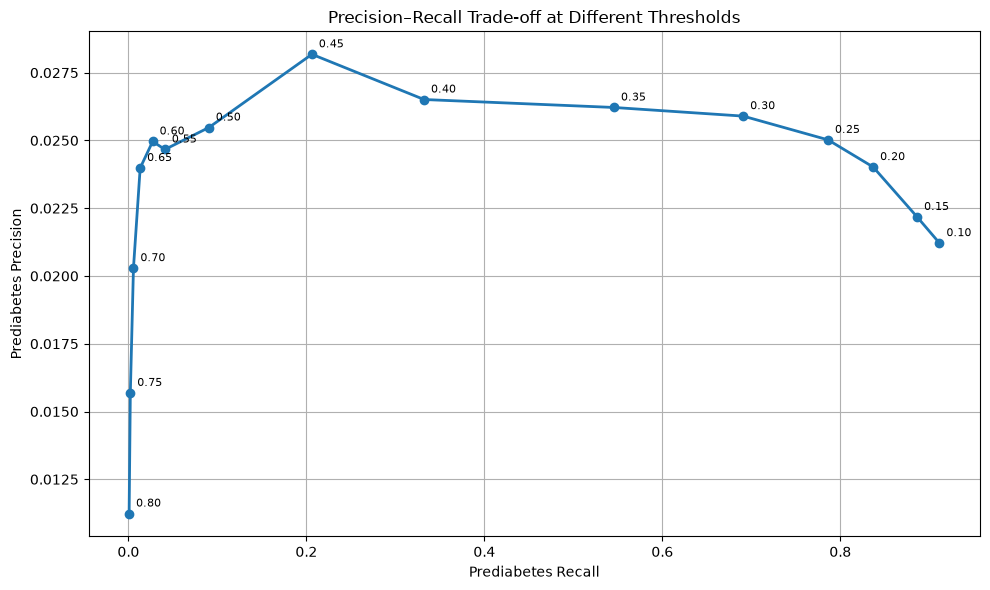

In [61]:
import matplotlib.pyplot as plt

# Plot precision against recall
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Recall"],
    threshold_df["Precision"],
    marker="o",
    linewidth=2
)

# Annotate each point with its threshold
for _, row in threshold_df.iterrows():
    plt.annotate(
        f'{row["Threshold"]:.2f}',
        (row["Recall"], row["Precision"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Prediabetes Recall")
plt.ylabel("Prediabetes Precision")
plt.title("Precision–Recall Trade-off at Different Thresholds")

plt.grid(True)
plt.tight_layout()
plt.show()

## Unsupervised Clustering of Health Profiles

This experiment investigates whether individuals in the dataset can be
grouped according to similarities in their health and lifestyle
indicators before classification.

The clustering process does not use the diabetes target variable.
Instead, it uses the predictor features to discover groups of similar
health profiles.

Categorical variables are transformed using one-hot encoding, while
numerical variables are standardised so that differences in measurement
scales do not dominate the clustering process.

After clustering, the actual diabetes categories are examined within
each group to determine whether the discovered clusters contain
meaningful patterns associated with no diabetes, prediabetes and
diabetes.

In [62]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import MiniBatchKMeans

# Separate categorical and numerical predictors
numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Categorical features:", len(categorical_features))
print("Numerical features:", numerical_features)

# Prepare preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ],
    sparse_threshold=1.0
)

# Transform training features only
X_train_cluster_ready = preprocessor.fit_transform(X_train)

print("\nTransformed feature matrix shape:",
      X_train_cluster_ready.shape)

# Perform MiniBatch K-Means clustering
kmeans = MiniBatchKMeans(
    n_clusters=6,
    random_state=42,
    batch_size=4096,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_train_cluster_ready)

# Store cluster assignments
cluster_results = pd.DataFrame({
    "Cluster": cluster_labels,
    "Actual_Class": y_train.to_numpy()
})

print("\nClustering completed successfully.")

print("\nNumber of records in each cluster:")
print(cluster_results["Cluster"].value_counts().sort_index())

Categorical features: 18
Numerical features: ['BMI', 'MentHlth', 'PhysHlth']

Transformed feature matrix shape: (202944, 63)

Clustering completed successfully.

Number of records in each cluster:
Cluster
0    62005
1    14744
2    38228
3    43778
4    27595
5    16594
Name: count, dtype: int64


## Analysis of Diabetes Categories Across Discovered Clusters

After discovering six clusters using health and lifestyle indicators,
we examine the distribution of the actual diabetes categories within
each cluster.

The purpose is to determine whether the discovered health-profile
groups contain different proportions of individuals without diabetes,
with prediabetes and with diabetes.

This analysis will help establish whether clustering reveals useful
patterns that may support the subsequent classification process.

The target variable is used only for evaluating cluster composition,
not for creating the clusters.

In [63]:
import pandas as pd

# Create a contingency table of clusters against actual classes
cluster_class_counts = pd.crosstab(
    cluster_results["Cluster"],
    cluster_results["Actual_Class"]
)

# Rename columns for clarity
cluster_class_counts.columns = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

print("ACTUAL DIABETES CATEGORY COUNTS PER CLUSTER")

display(cluster_class_counts)

# Calculate class percentages within each cluster
cluster_class_percentages = (
    cluster_class_counts
    .div(cluster_class_counts.sum(axis=1), axis=0)
    * 100
)

print("\nPERCENTAGE DISTRIBUTION WITHIN EACH CLUSTER")

display(cluster_class_percentages.round(2))

# Examine prediabetes concentration
print("\nPREDIABETES REPRESENTATION PER CLUSTER")

prediabetes_analysis = pd.DataFrame({
    "Cluster Size": cluster_class_counts.sum(axis=1),
    "Prediabetes Count": cluster_class_counts["Prediabetes"],
    "Prediabetes Percentage": cluster_class_percentages["Prediabetes"]
})

display(
    prediabetes_analysis.sort_values(
        by="Prediabetes Percentage",
        ascending=False
    ).round(2)
)

ACTUAL DIABETES CATEGORY COUNTS PER CLUSTER


,No Diabetes,Prediabetes,Diabetes
Cluster,,,
0,59334,474,2197
1,10979,426,3339
2,35493,412,2323
3,34529,1114,8135
4,19266,838,7491
5,11361,441,4792



PERCENTAGE DISTRIBUTION WITHIN EACH CLUSTER


,No Diabetes,Prediabetes,Diabetes
Cluster,,,
0,95.69,0.76,3.54
1,74.46,2.89,22.65
2,92.85,1.08,6.08
3,78.87,2.54,18.58
4,69.82,3.04,27.15
5,68.46,2.66,28.88



PREDIABETES REPRESENTATION PER CLUSTER


,Cluster Size,Prediabetes Count,Prediabetes Percentage
Cluster,,,
4,27595,838,3.04
1,14744,426,2.89
5,16594,441,2.66
3,43778,1114,2.54
2,38228,412,1.08
0,62005,474,0.76


## Health Profile Characteristics of Discovered Clusters

Following the analysis of diabetes category distribution, this
experiment investigates the health and lifestyle characteristics
associated with each discovered cluster.

The objective is to identify differences between clusters with
higher and lower prediabetes concentrations.

We examine the distribution of selected health indicators and
numerical characteristics to understand the patterns represented
by the discovered groups.

This analysis helps determine whether clustering has revealed
meaningful health-profile differences that may support
classification.

In [64]:
# Combine original training features with cluster assignments
cluster_profiles = X_train.copy()

cluster_profiles["Cluster"] = cluster_labels

# Binary health indicators
binary_features = [
    "HighBP",
    "HighChol",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "DiffWalk"
]

# Calculate percentage of records with value 1 in each cluster
binary_profile = (
    cluster_profiles
    .groupby("Cluster")[binary_features]
    .mean()
    * 100
)

print("BINARY HEALTH INDICATOR DISTRIBUTION (%)")
display(binary_profile.round(2))

# Numerical feature summaries
numerical_profile = (
    cluster_profiles
    .groupby("Cluster")[["BMI", "MentHlth", "PhysHlth"]]
    .median()
)

print("\nMEDIAN NUMERICAL HEALTH INDICATORS")
display(numerical_profile.round(2))

# Age category distribution
age_distribution = pd.crosstab(
    cluster_profiles["Cluster"],
    cluster_profiles["Age"],
    normalize="index"
) * 100

print("\nAGE CATEGORY DISTRIBUTION (%)")
display(age_distribution.round(2))

BINARY HEALTH INDICATOR DISTRIBUTION (%)


,HighBP,HighChol,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,DiffWalk
Cluster,,,,,,,,,,
0,10.34,16.28,26.79,1.09,1.95,89.72,100.00,92.21,5.08,3.25
1,53.84,53.66,59.84,8.76,16.26,57.55,53.70,73.48,6.52,45.54
2,16.86,24.11,43.69,1.70,3.71,76.71,0.46,70.39,7.30,5.06
3,83.85,83.89,62.50,5.93,16.81,80.67,77.30,84.07,6.48,12.63
4,68.78,46.14,39.35,4.07,9.81,59.13,53.69,73.55,3.48,26.91
5,63.99,56.76,58.80,11.46,24.38,51.19,60.27,76.35,3.80,63.69



MEDIAN NUMERICAL HEALTH INDICATORS


,BMI,MentHlth,PhysHlth
Cluster,,,
0,25.0,0.0,0.0
1,29.0,30.0,14.0
2,26.0,0.0,0.0
3,27.0,0.0,0.0
4,37.0,0.0,0.0
5,29.0,0.0,30.0



AGE CATEGORY DISTRIBUTION (%)


Age,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0
Cluster,,,,,,,,,,,,,
0,3.44,4.45,6.51,7.67,8.21,9.31,11.27,12.08,11.65,9.62,6.29,4.24,5.28
1,2.29,2.75,4.63,5.90,7.05,9.55,13.73,15.30,14.44,10.36,6.33,3.98,3.68
2,4.10,4.83,6.24,7.21,8.47,9.76,11.76,11.84,11.80,9.91,6.50,4.05,3.55
3,0.30,0.49,1.08,1.69,2.48,3.68,6.81,10.46,14.50,18.37,16.07,11.40,12.68
4,1.28,2.36,4.10,5.39,6.72,8.48,11.20,13.19,14.20,14.20,9.32,5.50,4.06
5,0.51,0.89,1.47,2.43,3.48,5.41,9.44,12.89,14.62,14.71,12.34,9.36,12.44


## Classification Using Cluster-Enhanced Features

This experiment investigates whether incorporating health-profile
cluster membership improves diabetes-related classification.

The original dataset contains 21 predictors. An additional feature
representing the cluster assigned to each individual is introduced.

The cluster membership feature represents similarities between
individuals based on their health and lifestyle indicators.

A class-weighted Decision Tree is trained using the original predictors
and the additional cluster feature.

Its performance is compared with the class-weighted Decision Tree
trained using only the original predictors.

The main evaluation measures are prediabetes precision, recall,
F1-score and overall Macro F1-score.

In [65]:
import pandas as pd

from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Copy the original training predictors
X_train_clustered = X_train.copy()

# Add the discovered cluster assignments
X_train_clustered["Cluster"] = cluster_labels

# One-hot encode cluster membership
cluster_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

cluster_encoded = cluster_encoder.fit_transform(
    X_train_clustered[["Cluster"]]
)

# Create a DataFrame for the encoded cluster features
cluster_feature_names = [
    f"Cluster_{int(value)}"
    for value in cluster_encoder.categories_[0]
]

cluster_encoded_df = pd.DataFrame(
    cluster_encoded,
    columns=cluster_feature_names,
    index=X_train.index
)

# Combine original predictors with encoded cluster features
X_train_cluster_enhanced = pd.concat(
    [
        X_train,
        cluster_encoded_df
    ],
    axis=1
)

print("Original feature shape:", X_train.shape)

print("Cluster-enhanced feature shape:",
      X_train_cluster_enhanced.shape)

print("\nAdditional cluster features:")
print(cluster_feature_names)

Original feature shape: (202944, 21)
Cluster-enhanced feature shape: (202944, 27)

Additional cluster features:
['Cluster_0', 'Cluster_1', 'Cluster_2', 'Cluster_3', 'Cluster_4', 'Cluster_5']


### Training and Evaluation of the Cluster-Enhanced Decision Tree

A class-weighted Decision Tree is trained using the original
health indicators together with the six encoded cluster membership
features.

Five-fold stratified cross-validation is used to evaluate the model.

The results are compared with the baseline class-weighted Decision
Tree to determine whether cluster membership contributes useful
information to diabetes-related classification.

In [66]:
# Create the cluster-enhanced Decision Tree
dt_cluster_enhanced = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    random_state=42
)

# Evaluate using five-fold cross-validation
cluster_cv_results = cross_validate(
    dt_cluster_enhanced,
    X_train_cluster_enhanced,
    y_train,
    cv=cv,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy"
    },
    n_jobs=-1,
    return_train_score=False,
    verbose=2
)

# Display results
print("CLUSTER-ENHANCED DECISION TREE RESULTS")

print("Fold Macro F1:", cluster_cv_results["test_macro_f1"])
print("Mean Macro F1:", cluster_cv_results["test_macro_f1"].mean())
print("Macro F1 Standard Deviation:",
      cluster_cv_results["test_macro_f1"].std())

print("\nFold Accuracy:", cluster_cv_results["test_accuracy"])
print("Mean Accuracy:", cluster_cv_results["test_accuracy"].mean())

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


CLUSTER-ENHANCED DECISION TREE RESULTS
Fold Macro F1: [0.40478363 0.39650039 0.39488326 0.40758009 0.39784052]
Mean Macro F1: 0.400317577419421
Macro F1 Standard Deviation: 0.004958391609578835

Fold Accuracy: [0.5954569  0.58045283 0.57890069 0.59585109 0.5790135 ]
Mean Accuracy: 0.5859350021606915


[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:    9.9s remaining:    6.6s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:   10.0s finished


In [67]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

# Generate out-of-fold predictions
dt_cluster_oof_predictions = cross_val_predict(
    dt_cluster_enhanced,
    X_train_cluster_enhanced,
    y_train,
    cv=cv,
    n_jobs=-1,
    verbose=2
)

# Display class-level performance
print("CLUSTER-ENHANCED DECISION TREE")
print(classification_report(
    y_train,
    dt_cluster_oof_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    digits=4
))

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_train, dt_cluster_oof_predictions))

# Calculate prediabetes metrics
from sklearn.metrics import precision_score, recall_score, f1_score

print("\nPREDIABETES PERFORMANCE")
print("Precision:", precision_score(
    y_train, dt_cluster_oof_predictions, labels=[1], average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_train, dt_cluster_oof_predictions, labels=[1], average="macro", zero_division=0
))
print("F1-score:", f1_score(
    y_train, dt_cluster_oof_predictions, labels=[1], average="macro", zero_division=0
))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   5 | elapsed:    6.8s remaining:    4.5s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    6.9s finished


CLUSTER-ENHANCED DECISION TREE
              precision    recall  f1-score   support

 No diabetes     0.9526    0.5911    0.7295    170962
 Prediabetes     0.0259    0.3252    0.0480      3705
    Diabetes     0.3308    0.5891    0.4237     28277

    accuracy                         0.5859    202944
   macro avg     0.4364    0.5018    0.4004    202944
weighted avg     0.8490    0.5859    0.6744    202944

Confusion Matrix:
[[101049  37801  32112]
 [   918   1205   1582]
 [  4110   7509  16658]]

PREDIABETES PERFORMANCE
Precision: 0.025905621842416425
Recall: 0.3252361673414305
F1-score: 0.047988849064117885


In [68]:
import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Original Decision Tree",
        "Evaluation": "Held-out test set",
        "Macro F1": 0.4026,
        "Accuracy": 0.7668,
        "Prediabetes Precision": 0.0284,
        "Prediabetes Recall": 0.0378
    },
    {
        "Model": "SMOTENC Decision Tree",
        "Evaluation": "5-fold CV",
        "Macro F1": 0.4021,
        "Accuracy": 0.7397,
        "Prediabetes Precision": 0.0268,
        "Prediabetes Recall": 0.0648
    },
    {
        "Model": "SMOTENC Random Forest",
        "Evaluation": "5-fold CV",
        "Macro F1": 0.4404,
        "Accuracy": 0.7969,
        "Prediabetes Precision": 0.0291,
        "Prediabetes Recall": 0.0227
    },
    {
        "Model": "Balanced Random Forest",
        "Evaluation": "5-fold CV",
        "Macro F1": 0.4414,
        "Accuracy": 0.7917,
        "Prediabetes Precision": 0.0198,
        "Prediabetes Recall": 0.0051
    },
    {
        "Model": "Class-weighted Decision Tree",
        "Evaluation": "5-fold CV",
        "Macro F1": 0.3989,
        "Accuracy": 0.5818,
        "Prediabetes Precision": 0.0256,
        "Prediabetes Recall": 0.3250
    },
    {
        "Model": "Cluster-enhanced Decision Tree",
        "Evaluation": "5-fold CV (exploratory)",
        "Macro F1": 0.4003,
        "Accuracy": 0.5859,
        "Prediabetes Precision": 0.0259,
        "Prediabetes Recall": 0.3252
    }
])

# Format scores as percentages
formatted_comparison = model_comparison.copy()

for column in [
    "Macro F1",
    "Accuracy",
    "Prediabetes Precision",
    "Prediabetes Recall"
]:
    formatted_comparison[column] = (
        formatted_comparison[column] * 100
    ).round(2).astype(str) + "%"

display(formatted_comparison)

,Model,Evaluation,Macro F1,Accuracy,Prediabetes Precision,Prediabetes Recall
0,Original Decision Tree,Held-out test set,40.26%,76.68%,2.84%,3.78%
1,SMOTENC Decision Tree,5-fold CV,40.21%,73.97%,2.68%,6.48%
2,SMOTENC Random Forest,5-fold CV,44.04%,79.69%,2.91%,2.27%
3,Balanced Random Forest,5-fold CV,44.14%,79.17%,1.98%,0.51%
4,Class-weighted Decision Tree,5-fold CV,39.89%,58.18%,2.56%,32.5%
5,Cluster-enhanced Decision Tree,5-fold CV (exploratory),40.03%,58.59%,2.59%,32.52%



## Model Comparison and Evaluation

Six classification experiments were conducted to investigate how different approaches handle the imbalanced diabetes dataset. The models were evaluated using Macro F1, accuracy, prediabetes precision, and prediabetes recall.

Macro F1 was considered important because the dataset contains three classes with significantly different numbers of observations. Accuracy alone would not adequately show how well the models identify the minority prediabetes class.

### Comparison of Model Performance

| Model | Evaluation | Macro F1 | Accuracy | Prediabetes Precision | Prediabetes Recall |
|---|---|---:|---:|---:|---:|
| Original Decision Tree | Held-out test | 40.26% | 76.68% | 2.84% | 3.78% |
| SMOTENC Decision Tree | 5-fold CV | 40.21% | 73.97% | 2.68% | 6.48% |
| SMOTENC Random Forest | 5-fold CV | 44.04% | 79.69% | 2.91% | 2.27% |
| Balanced Random Forest | 5-fold CV | 44.14% | 79.17% | 1.98% | 0.51% |
| Class-weighted Decision Tree | 5-fold CV | 39.89% | 58.18% | 2.56% | 32.50% |
| Cluster-enhanced Decision Tree | 5-fold CV (exploratory) | 40.03% | 58.59% | 2.59% | 32.52% |

### Interpretation of Results

The Random Forest models achieved the highest overall Macro F1 scores. The Balanced Random Forest obtained 44.14%, while the SMOTENC Random Forest obtained 44.04%. These results indicate stronger overall classification performance across the three classes compared with the Decision Tree experiments.

However, both Random Forest models had very low prediabetes recall. The Balanced Random Forest detected only 0.51% of actual prediabetes cases, while the SMOTENC Random Forest detected 2.27%. This demonstrates that stronger overall classification performance does not necessarily translate into effective detection of the minority class.

The class-weighted Decision Tree achieved a considerably higher prediabetes recall of 32.50%. This suggests that assigning greater importance to underrepresented classes helped the model identify more prediabetes cases. However, its precision was only 2.56%, indicating that a large proportion of its prediabetes predictions were incorrect.

The clustering experiment produced a similar result. The cluster-enhanced Decision Tree achieved 32.52% prediabetes recall and 40.03% Macro F1. The improvement over the original class-weighted Decision Tree was very small. Therefore, adding cluster membership features did not demonstrate a meaningful improvement in predictive performance.

### Model Selection

The Balanced Random Forest achieved the highest Macro F1, making it the strongest candidate for overall classification performance among the cross-validation experiments.

The class-weighted Decision Tree demonstrated the strongest prediabetes detection performance among the simpler classification experiments, achieving 32.50% recall.

For the HealthAware project's focus on identifying possible prediabetes cases, the class-weighted Decision Tree is therefore a useful candidate for further investigation. However, its low precision and high false-positive rate mean that it cannot yet be considered a reliable screening model.

The results also demonstrate that model selection should consider the project's intended objective rather than relying on accuracy alone.

### Evaluation Limitations

The original Decision Tree was evaluated using a held-out test set, whereas the other models were evaluated using five-fold cross-validation. Their scores should therefore not be treated as a perfectly controlled comparison.

Additionally, the cluster-enhanced experiment is exploratory because clustering was performed before cross-validation. A more rigorous evaluation would fit the clustering transformation separately within each training fold.

Finally, the dataset is based on U.S. BRFSS survey data. Its findings should not automatically be generalised to the Kenyan population or interpreted as clinical diagnoses.



## Final Model Selection

Following the evaluation of six classification experiments, the Class-weighted Decision Tree was selected as the leading model for the HealthAware project.

The selection was based primarily on its ability to identify prediabetes cases. It achieved a prediabetes recall of 32.50%, considerably higher than the other evaluated models.

Although the Balanced Random Forest achieved the highest Macro F1 score of 44.14%, its prediabetes recall was only 0.51%. This indicated that it performed better overall but was less effective at identifying the minority prediabetes class.

The Cluster-enhanced Decision Tree achieved a similar prediabetes recall of 32.52%, but the improvement over the Class-weighted Decision Tree was negligible. Therefore, the additional clustering features were not retained in the selected model.

The selected Class-weighted Decision Tree achieved:
- Macro F1: 39.89%
- Accuracy: 58.18%
- Prediabetes precision: 2.56%
- Prediabetes recall: 32.50%

Despite its higher recall, the model has a substantial false-positive rate. Consequently, it should be treated as an experimental screening-support model rather than a diagnostic system. Further validation and improvement of precision are necessary before practical deployment.


In [69]:
import joblib
from pathlib import Path

# Create the final model using the selected configuration
final_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    random_state=42
)

# Train using the complete training dataset
final_model.fit(X_train, y_train)

# Create a directory for saved models
model_directory = Path("models")
model_directory.mkdir(exist_ok=True)

# Save the trained model
model_path = model_directory / "healthaware_diabetes_model.joblib"

joblib.dump(final_model, model_path)

print("FINAL MODEL TRAINED AND SAVED")
print("Model:", final_model)
print("Training observations:", X_train.shape[0])
print("Number of features:", X_train.shape[1])
print("Saved location:", model_path)
print("Classes:", final_model.classes_)

FINAL MODEL TRAINED AND SAVED
Model: DecisionTreeClassifier(class_weight='balanced', max_depth=8, random_state=42)
Training observations: 202944
Number of features: 21
Saved location: models\healthaware_diabetes_model.joblib
Classes: [0. 1. 2.]



## Final Model Evaluation on the Test Dataset

The selected Class-weighted Decision Tree was evaluated using the test dataset, which was separated from the training dataset during the initial data splitting process.

The evaluation uses accuracy, precision, recall, F1-score and a confusion matrix to examine the model's classification performance across the three diabetes-related categories.

Particular attention is given to the prediabetes class because it is the minority class and is an important focus of the HealthAware project.

The test dataset was also used in earlier model experiments. Therefore, these results should be interpreted with this limitation in mind and should not be considered an entirely independent final validation.


FINAL MODEL TEST RESULTS
Accuracy: 0.6032

Classification Report:
              precision    recall  f1-score   support

 No diabetes     0.9528    0.6087    0.7428     42741
 Prediabetes     0.0266    0.2927    0.0487       926
    Diabetes     0.3266    0.6111    0.4257      7069

    accuracy                         0.6032     50736
   macro avg     0.4353    0.5041    0.4057     50736
weighted avg     0.8487    0.6032    0.6860     50736


Confusion Matrix:
[[26015  8239  8487]
 [  234   271   421]
 [ 1054  1695  4320]]


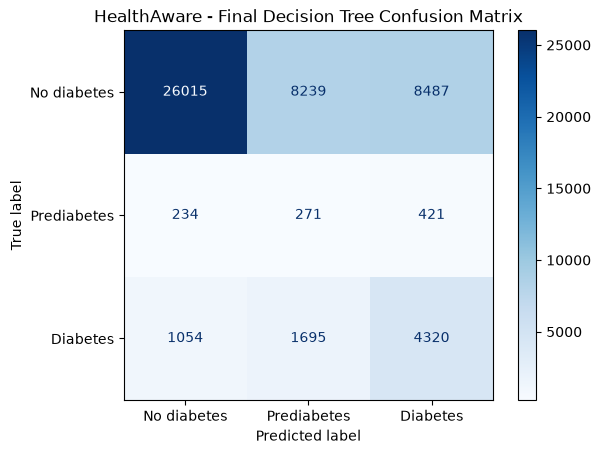

In [70]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions on the test dataset
y_test_predictions = final_model.predict(X_test)

# Calculate accuracy
test_accuracy = accuracy_score(y_test, y_test_predictions)

print("FINAL MODEL TEST RESULTS")
print("Accuracy:", round(test_accuracy, 4))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_predictions,
    target_names=["No diabetes", "Prediabetes", "Diabetes"],
    digits=4
))

# Display confusion matrix
cm = confusion_matrix(y_test, y_test_predictions)

print("\nConfusion Matrix:")
print(cm)

# Visualise confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No diabetes", "Prediabetes", "Diabetes"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("HealthAware - Final Decision Tree Confusion Matrix")
plt.show()


### Final Evaluation Conclusion

The final Class-weighted Decision Tree achieved an accuracy of 60.32% and a Macro F1-score of 40.57% on the test dataset.

The model correctly classified 271 out of 926 actual prediabetes cases, resulting in a prediabetes recall of 29.27%. Although this demonstrates some ability to identify prediabetes cases, the precision of 2.66% indicates that most observations predicted as prediabetes were incorrectly classified.

The model achieved a recall of 61.11% for the diabetes class and 60.87% for the no-diabetes class.

The comparison between cross-validation and test results showed relatively similar overall performance. However, the reduction in prediabetes recall from 32.50% during cross-validation to 29.27% on the test set highlights the difficulty of identifying the minority class.

Overall, the model demonstrates the potential of class weighting to improve minority-class detection. Nevertheless, its high false-positive rate limits its suitability for practical screening.

The model is therefore retained as an experimental candidate for HealthAware, not as a clinically validated diagnostic or screening system. Further work should focus on improving prediabetes precision, validating the model on independent data, and assessing its suitability for the intended population.
